# hiNiche: Simulated colorectal cancer TME (no reference, top-5000 HVG input)

Same pipeline as `HDST_sim_TME_run_hiNiche.ipynb`, with two differences in the input:

- **No reference**: `ref_matrix=None`, so the loss contains only the contrastive term (no Poisson NLL / entropy).
- **Input genes = top 5000 highly variable genes (HVG)** instead of the genes shared with the reference.

The simulated AnnData provides the ground truth used for evaluation:

- `obsm["S_s2c"]`: spot-to-cell assignment
- `obs["niche_id"]`: ground-truth niche of each spot

## 1. Setup and imports

In [1]:
import os
import sys
# cupy (used by rapids_singlecell) compiles GPU kernels at runtime and needs the CUDA headers shipped inside the conda environment
os.environ.setdefault("CUDA_PATH", os.path.join(sys.prefix, "targets", "x86_64-linux"))

# --- Project modules ---
import config
import utils
from train import run_train_seq

# --- Standard library ---
import warnings

# --- Data handling ---
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc

# --- Deep learning ---
import torch

# --- Clustering and evaluation ---
import rapids_singlecell as rsc     # GPU-accelerated neighbors / UMAP
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score as NMI, adjusted_rand_score as ARI

# --- Plotting ---
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

/hpc/home/wz220/miniconda3/envs/hiNiche/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Parameter configuration

In [2]:
SAMPLE = "Simulation1_HD"

# Data path (no reference file is used)
h5_path = f"DATA/{SAMPLE}/sim_TME.h5ad"

# Patch save path (separate from the reference-based run)
PATCH_LOC = f"DATA/{SAMPLE}/mini_batch_cache_hvg5000"

# Model save path (an existing checkpoint is loaded instead of retraining)
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint_hvg5000_noref.pt"

# Color map defined in config.py
umap_color = getattr(config, "umap_40")

# Input genes
N_HVG = 5000      # number of highly variable genes used as model input

# Model / training hyperparameters
graph_knn   = 12
niche_knn   = 20
lr          = 0.005
hidden_dim  = 32  # embedding dimension (free to choose without a reference)
num_epochs  = 100
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
alpha       = 1
beta        = 1
seed        = 42
device      = "cuda:0"

# Niche clustering
n_clusters = 5    # number of KMeans clusters (= number of simulated niches)
emb_k      = 50   # n_neighbors of the kNN graph used for UMAP only

## 3. Data loading and preprocessing

### 3.1 Load simulated data

In [3]:
# Simulated spot-level counts
adata = sc.read(h5_path)
print(adata)

AnnData object with n_obs × n_vars = 360000 × 6008
    obs: 'spotid', 'celltype', 'x', 'y', 'cell_id', 'niche_id', 'niche_name'
    uns: 'cells', 'celltype_names', 'niche_compositions', 'niche_names', 'pattern', 'spatial_neighbors'
    obsm: 'S_s2c', 'spatial_grid'
    layers: 'counts_clean'
    obsp: 'spatial_connectivities', 'spatial_distances'


### 3.2 Normalization

In [4]:
# Keep raw counts before normalization
adata.layers["counts"] = adata.X.copy()
adata.var_names_make_unique()

# Library-size normalization + log transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

### 3.3 Select highly variable genes

In [5]:
# Top-N HVG on the log-normalized data (replaces the intersection with the reference)
sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat")
hvg_mask = adata.var["highly_variable"].values
n_hvg = int(hvg_mask.sum())
print(f"[Log] input gene number is {n_hvg}")

adata.obsm["X_mle"] = adata.layers["counts"][:, hvg_mask]   # raw counts (unused in the loss without a reference)
adata.obsm["X_input"] = adata[:, hvg_mask].X                # normalized model input

# No reference: contrastive loss only
ref_matrix = None

[Log] input gene number is 5000


## 4. Build the spot / cell / niche hierarchy

### 4.1 Spot-to-cell and spot-to-niche assignment

In [6]:
# Spot -> cell assignment taken from the simulation (ground-truth cell segmentation)
S_s2c_all, cell_background_mask = utils.spot2cell_from_assignment(adata.obsm["S_s2c"], max_spots_per_cell=200, min_spots_per_cell=1)
print(f"[Log] {S_s2c_all.shape[1]} cells are detected")

# Spot -> niche assignment: each niche is a cell plus its nearest neighbors (including itself)
S_s2n_all, niche_background_mask, active_niche_indices, S_c2n_all = utils.spot2niche_by_cell_knn(adata.obsm["spatial_grid"], S_s2c_all, k_niche=niche_knn)
background_mask = {"cell": cell_background_mask, "niche": niche_background_mask}

[Log] Active Cells (before filtering): 8030
[Log] Valid Cells (1 <= spots <= 200): 8030
[Log] Filtered Cells (< 1 spots): 0
[Log] Filtered Cells (> 200 spots): 0
[Log] 8030 cells are detected
[Log] Active Niches: 8030, Cells per Niche (k): 20


### 4.2 Spatial KNN graphs

In [7]:
# Spatial KNN graphs at spot and cell level
spot_edges = utils.build_spot_knn_graph(adata.obsm["spatial_grid"], graph_knn)
cell_edges = utils.build_cell_knn_graph(adata.obsm["spatial_grid"], S_s2c_all, graph_knn)
# Niche graph: reuses the cell KNN graph (one niche per cell), same k as spot/cell graphs
niche_edges = cell_edges

[Log] 4330462 edges generated from 360000 nodes (k=12)
[Log] 107126 edges generated from 8030 nodes (k=12)


### 4.3 Spatial blocking and subgraph caching

In [8]:
# Split the slide into overlapping spatial blocks (core + halo) for mini-batch training
batch_mask, block_ids = utils.make_block_masks(adata.obsm["spatial_grid"], S_s2c=S_s2c_all, S_s2n=S_s2n_all, single_patch = True)

# Build and cache per-block subgraph data to disk (ref_matrix=None skips likelihood precomputation)
utils.build_subgraph_data(adata, ref_matrix, spot_edges, cell_edges, niche_edges,
                          S_s2c_all, S_s2n_all, S_c2n_all, background_mask, batch_mask, block_ids, PATCH_LOC)
print(f"[Log] Original ST is patchfied to {len(block_ids)} blocks with avg {batch_mask['spot_level_core'].sum(dim=1).float().mean().item():.0f} spots, {batch_mask['cell_level_core'].sum(dim=1).float().mean().item():.0f} cells and {batch_mask['niche_level_core'].sum(dim=1).float().mean().item():.0f} niches per block")

[Log] Single-patch mode: the whole slide is one block


[Log] Building & saving mini-batches: 100%|██████████| 1/1 [00:06<00:00,  6.42s/it]

[Log] Saved 1 blocks → DATA/Simulation1_HD/mini_batch_cache_hvg5000
[Log] Original ST is patchfied to 1 blocks with avg 360000 spots, 8030 cells and 8030 niches per block


## 5. Model training

In [9]:
emb_all, slice_id = run_train_seq(total_unit_number_per_level = {"spot": S_s2c_all.shape[0], "cell": S_s2c_all.shape[1], "niche": S_s2n_all.shape[1]},
                                  PATCH_LOC = PATCH_LOC,
                                  MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                                  ref_matrix = ref_matrix,
                                  lr = lr,
                                  in_dim = n_hvg,
                                  hidden_dim = hidden_dim,
                                  num_epochs = num_epochs,
                                  edge_drop = edge_drop,
                                  member_drop = member_drop,
                                  neg_samples = neg_samples,
                                  tau = tau,
                                  alpha = alpha,
                                  beta = beta,
                                  seed = seed,
                                  device = device)

Epoch 100: 100%|██████████| 1/1 [00:00<00:00,  2.14it/s, cl=4.4353, nll=0.0000, entp=0.0000]


Training finished!
Model saved to DATA/Simulation1_HD/checkpoint_hvg5000_noref.pt


generating embeddings (slice 0)...: 100%|██████████| 1/1 [00:00<00:00,  2.01it/s]


## 6. Niche detection

### 6.1 Niche clustering (UMAP + spatial map) and NMI / ARI

niche: 5 clusters
spots with a niche label: 320110 / 360000


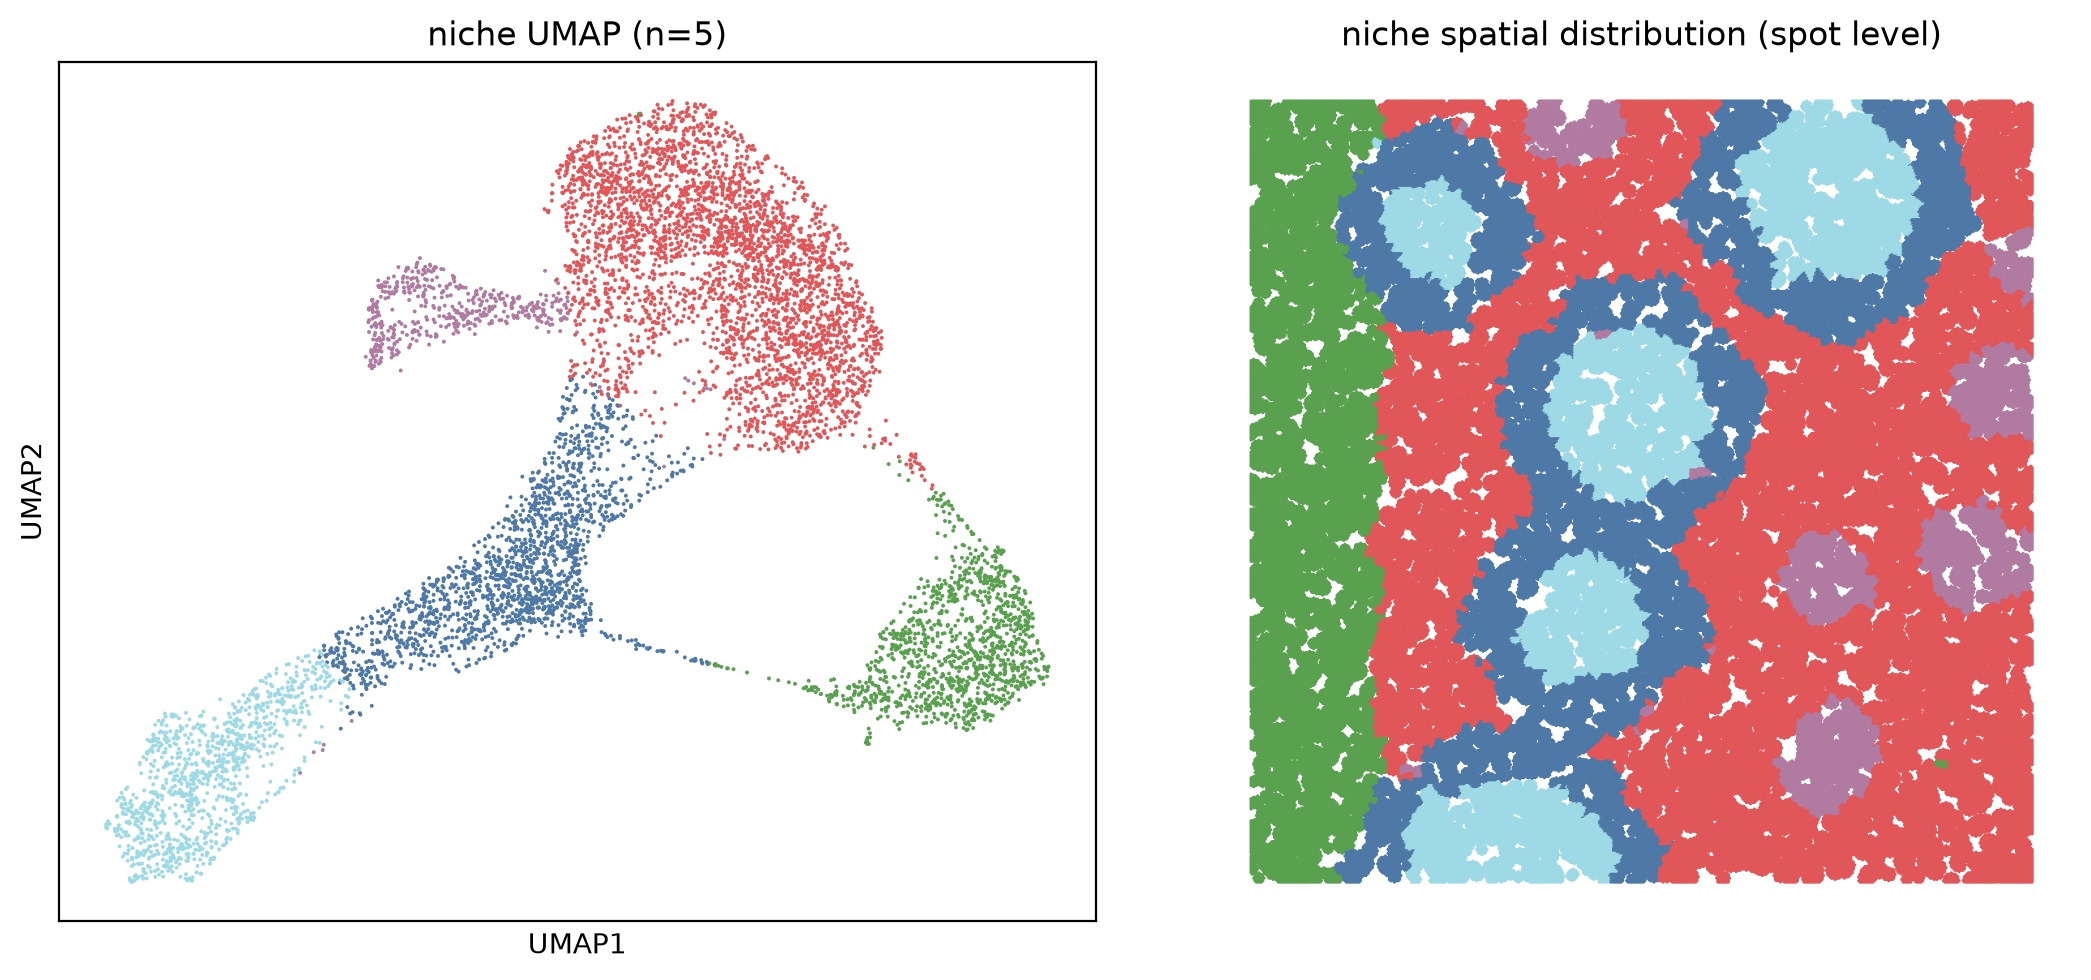

evaluated cells: 8030 / 8030
GT niches: 5,  pred niches: 5
NMI = 0.8383
ARI = 0.8689


In [10]:
torch.cuda.empty_cache()

# --- 1. Niche embedding: KMeans clustering + UMAP ---
X_niche = emb_all["niche"].numpy()
niche_label = KMeans(n_clusters=n_clusters, random_state=seed, n_init=20).fit_predict(X_niche)

adata_tmp = ad.AnnData(X_niche)
rsc.pp.neighbors(adata_tmp, use_rep='X', n_neighbors=emb_k)
rsc.tl.umap(adata_tmp, random_state=seed)
niche_umap = adata_tmp.obsm["X_umap"]

clusters_id = {"niche": niche_label}
print(f"niche: {len(np.unique(niche_label))} clusters")

# --- 2. Map niche clusters back to their center cells ---
S = S_s2c_all.coalesce()
rows, cols = S.indices()[0], S.indices()[1]
n_cell = S.size(1)

cell_niche = torch.full((n_cell,), -1, dtype=torch.long, device=S.device)
active = torch.as_tensor(active_niche_indices, device=S.device).long()
cell_niche[active] = torch.as_tensor(niche_label, device=S.device).long()

# --- 3. Broadcast to spots (each spot takes the niche of its cell) ---
spot2cell = torch.full((S.size(0),), -1, dtype=torch.long, device=S.device)
spot2cell[rows] = cols
spot_niche = torch.where(spot2cell >= 0,
                         cell_niche[spot2cell],
                         torch.tensor(-1, dtype=torch.long, device=S.device)).cpu().numpy()

xy = np.asarray(adata.obsm["spatial_grid"])
keep_spot = spot_niche >= 0
print(f"spots with a niche label: {keep_spot.sum()} / {len(xy)}")

# --- 4. Left: niche UMAP; right: spot-level niche spatial distribution ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=200)

axes[0].scatter(niche_umap[:, 0], niche_umap[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in niche_label], s=2, linewidths=0)
axes[0].set_title(f"niche UMAP (n={n_clusters})")
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_xlabel("UMAP1"); axes[0].set_ylabel("UMAP2")

axes[1].scatter(xy[keep_spot, 0], xy[keep_spot, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in spot_niche[keep_spot]],
                s=5, marker='.', linewidths=0)
axes[1].set_title("niche spatial distribution (spot level)")
axes[1].invert_yaxis(); axes[1].set_aspect("equal"); axes[1].axis("off")

plt.tight_layout()
plt.show()

# ==================== NMI / ARI (cell-level evaluation) ====================
s_rows = S.indices()[0].cpu().numpy()
c_cols = S.indices()[1].cpu().numpy()

# --- Ground truth: spot niche -> majority vote per cell ---
gt_spot = pd.factorize(adata.obs["niche_id"].values)[0]          # integer labels
maj = pd.DataFrame({"cell": c_cols, "gt": gt_spot[s_rows]}).groupby("cell")["gt"].agg(lambda x: np.bincount(x).argmax())
gt_cell = np.full(n_cell, -1, dtype=np.int64)
gt_cell[maj.index.values] = maj.values

# --- Prediction: niche cluster of each cell ---
pred_cell = cell_niche.cpu().numpy()

mask = (pred_cell >= 0) & (gt_cell >= 0)
print(f"evaluated cells: {mask.sum()} / {n_cell}")
print(f"GT niches: {len(np.unique(gt_cell[mask]))},  pred niches: {len(np.unique(pred_cell[mask]))}")
print(f"NMI = {NMI(gt_cell[mask], pred_cell[mask]):.4f}")
print(f"ARI = {ARI(gt_cell[mask], pred_cell[mask]):.4f}")